In [63]:
import pandas as pd 
import seaborn as sns
import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import matplotlib.pyplot as plt

FUNCTION

In [64]:
def clean(data):
    df = pd.DataFrame(columns=['Year', 'Age', 'Female', 'Male', 'Total'])

    for i in range(len(data)):
        row = data.iloc[i, 0].split()
        df.loc[len(df)] = row
    
    for column in df.columns:
        if df[column].dtype == "object":
            df[column] = df[column].str.replace(r'[+-]', '', regex=True)
    
    for column in df.columns:
        df[column] = pd.to_numeric(df[column], errors='coerce') # coerce = jika gagal data jadi nan
        
    df = df.fillna(0)
    
    df = df.drop_duplicates(subset=["Year","Age"]).reset_index(drop = True)
    
    return df

def whittaker_henderson(y, lambda_, d=2):
    n = len(y)
    E = sp.eye(n)
    D = sp.diags([1, -2, 1], [0, 1, 2], shape=(n - 2, n))
    
    # Matriks penalti
    P = lambda_ * D.T @ D
    
    # Menyelesaikan sistem persamaan
    Z = E + P
    z = spla.spsolve(Z, y)
    
    return z

DEATHS

In [65]:
belgium_death = clean(pd.read_csv("Data pembanding/Belgium/Belgium, Deaths (period 1x1),.txt", delimiter = "\t"))
belgium_population = clean(pd.read_csv("Data pembanding/Belgium/Belgium, Population size.txt", delimiter = "\t"))

BACKUP

In [66]:
backup_bel_death = belgium_death.copy()
backup_bel_population = belgium_population.copy()

selisih = len(belgium_population) - len(belgium_death)
backup_bel_population = backup_bel_population[:-selisih].reset_index(drop = True)

backup_bel_death = backup_bel_death[backup_bel_death["Age"] < 103].reset_index(drop=True)
backup_bel_population = backup_bel_population[backup_bel_population["Age"] < 103].reset_index(drop=True)

FEMALE

WHITE TAKER

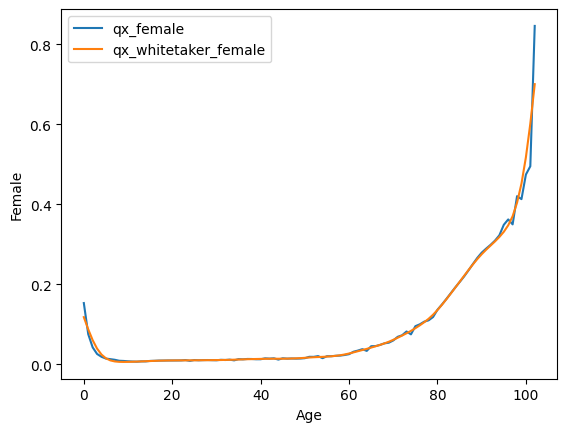

In [67]:
# pakai fillna karena 0.0 / 0.0 hasil nan jadi jika nan diberi angka 0

qx_female = (backup_bel_death["Female"] / backup_bel_population["Female"]).fillna(0) 
qx_male = (backup_bel_death["Male"] / backup_bel_population["Male"]).fillna(0) 

qx_head_female = qx_female.head(111)
qx_1841_female = qx_head_female[:-8]

smoothed_qx_female = whittaker_henderson(qx_1841_female, 10)

age = backup_bel_death["Age"].head(103)

sns.lineplot(x = age, y = qx_1841_female, label = "qx_female")
sns.lineplot(x = age, y = smoothed_qx_female, label = "qx_whitetaker_female")
plt.legend()

LAMBDA

In [68]:
dx_female = backup_bel_death["Female"].drop(index=range(7519, 8034)).reset_index(drop=True)
L_female = backup_bel_population["Female"].drop(index=range(7519, 8034)).reset_index(drop=True)
smoothed_double_female = np.tile(smoothed_qx_female, 177)
selisih_smoothed = len(smoothed_double_female) - len(L_female)
t = backup_bel_death["Year"].drop(index=range(7519, 8034)).reset_index(drop=True)
t0 = 1841

numerator = np.log(dx_female / (L_female * smoothed_double_female)) * (t - t0)

index = 103
data = []

for _ in range(103):
    hasil = 0
    for z in range(len(numerator)):
        if z == index:
            hasil += numerator[z]
    data.append(hasil)
    index += 1

numerator = pd.Series(data)
denominator = np.sum((t - t0) ** 2)
lambda_female = - numerator / denominator

lambda_female

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


0     -1.496478e-09
1      1.425367e-10
2      1.545382e-09
3      1.344352e-09
4      4.464857e-10
           ...     
98    -9.352878e-10
99    -1.920953e-09
100    8.389650e-10
101    5.218314e-11
102    3.480321e-10
Length: 103, dtype: float64

ALPHA

In [69]:
import numpy as np

tahun = np.arange(0, 178)

alpha = []

temp = 0

for i in range(177): # 0
    for z in range(len(lambda_female)):
        logika1 = dx_female[temp] / (L_female[temp] * smoothed_double_female[temp])
        logika2 = np.exp(-lambda_female.values[z] * tahun[i])
        logika3 = np.exp(-lambda_female.values[z] * tahun[i]) ** 2
        hasil = logika1 * logika2
        alpha.append(hasil / logika3)
        temp += 1
    
alpha

/var/folders/q2/2h4p204s56d3vhv_jx5hmc6m0000gn/T/ipykernel_3429/2647992995.py:11: RuntimeWarning: divide by zero encountered in scalar divide
  logika1 = dx_female[temp] / (L_female[temp] * smoothed_double_female[temp])
/var/folders/q2/2h4p204s56d3vhv_jx5hmc6m0000gn/T/ipykernel_3429/2647992995.py:11: RuntimeWarning: invalid value encountered in scalar divide
  logika1 = dx_female[temp] / (L_female[temp] * smoothed_double_female[temp])


[1.2989833929977523,
 0.8608408197305844,
 0.7009371858646951,
 0.657890761423248,
 0.769009505149726,
 0.9583160018146498,
 1.3245862647536202,
 1.5886572169165123,
 1.4497576411243493,
 1.4196338553301866,
 1.2387402770777338,
 1.0873897743088559,
 0.9746184648946631,
 1.0164429985167351,
 0.9472623263288749,
 1.0338841738859186,
 1.0157653171701926,
 1.0320455036480138,
 1.0069014070398075,
 1.008458517948327,
 0.9936833290758491,
 0.9904730545544063,
 0.9907609042061618,
 1.0713518583058341,
 0.8678917567982318,
 1.0605991739036171,
 0.9877936008390236,
 1.0172696907609964,
 1.0309670947285516,
 0.9882505651484308,
 0.9524300464352818,
 1.0476482508205505,
 0.97917119955566,
 1.0374860170485374,
 0.8509542446275657,
 1.0771032505678835,
 1.0020729430765567,
 1.0495446131009207,
 1.0177416724152497,
 0.9510145106908144,
 0.9329939058670591,
 1.084190298862667,
 1.0246133733643727,
 1.0765052721547788,
 0.8443499413440521,
 1.0733615597851403,
 0.9974481623351437,
 1.0076222158092474

QX

In [70]:
qx = []

for i in range(177):
    for z in range(len(smoothed_qx_female)):
        alpa = alpha[i]
        qxt0 = smoothed_qx_female[z]
        exponen = np.exp(-lambda_female.values[z] * tahun[i])
        hasil = alpa * qxt0 * exponen
        qx.append(hasil)

qx

[0.15302722703180954,
 0.11334423152618314,
 0.0782364959764575,
 0.05070199130378837,
 0.031398925763850984,
 0.019250945648394066,
 0.012456411909170559,
 0.009133439859585956,
 0.007804462834428755,
 0.007529560697349282,
 0.007719824991463404,
 0.00810231311832412,
 0.00858838579522979,
 0.009160209670957778,
 0.009778152752729462,
 0.010417645179169476,
 0.011002549386004461,
 0.011492027139034333,
 0.011862586072134109,
 0.012127560598939512,
 0.012308471986589124,
 0.012437099621121094,
 0.012537448031861723,
 0.012621672991178123,
 0.012690346803099745,
 0.01283409975394096,
 0.01297591218783827,
 0.013116538033216732,
 0.013240892302137142,
 0.013356541862229149,
 0.013512056777743486,
 0.013740313931085628,
 0.014009913413312945,
 0.014354925507936956,
 0.014780239529396343,
 0.015344555690361887,
 0.01588628100697992,
 0.016362134007621477,
 0.01673212635628015,
 0.017037335276840832,
 0.017348523583650775,
 0.01765299587055116,
 0.017821811050951795,
 0.017874649138078805,


PIVOT TABLE

In [71]:
tabel = backup_bel_death.drop(index=range(7519, 8034)).reset_index(drop=True)
tabel.drop(columns = ["Female", "Male", "Total"], inplace=True)
tabel["qx"] = qx
tabel.pivot(index='Age', columns='Year', values='qx')

Year,1841,1842,1843,1844,1845,1846,1847,1848,1849,1850,...,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022
Age,,,,,,,,,,,,,,,,,,,,,
0,0.153027,0.101412,0.082574,0.077503,0.090593,0.112895,0.156043,0.187152,0.170789,0.167241,...,0.125979,0.100456,0.127421,0.119803,0.118560,0.119074,0.112508,0.112588,0.119133,0.116234
1,0.113344,0.075114,0.061161,0.057405,0.067101,0.083619,0.115578,0.138620,0.126500,0.123872,...,0.093310,0.074406,0.094378,0.088735,0.087815,0.088196,0.083332,0.083391,0.088240,0.086092
2,0.078236,0.051848,0.042217,0.039624,0.046317,0.057718,0.079779,0.095683,0.087317,0.085503,...,0.064408,0.051359,0.065145,0.061250,0.060615,0.060878,0.057521,0.057561,0.060908,0.059426
3,0.050702,0.033600,0.027359,0.025679,0.030016,0.037405,0.051701,0.062009,0.056587,0.055411,...,0.041740,0.033284,0.042218,0.039694,0.039282,0.039452,0.037277,0.037303,0.039472,0.038511
4,0.031399,0.020808,0.016943,0.015902,0.018588,0.023164,0.032018,0.038401,0.035043,0.034315,...,0.025849,0.020612,0.026145,0.024582,0.024327,0.024432,0.023085,0.023101,0.024444,0.023850
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
98,0.524847,0.347818,0.283210,0.265817,0.310714,0.387202,0.535192,0.641888,0.585767,0.573595,...,0.432078,0.344540,0.437023,0.410895,0.406632,0.408396,0.385875,0.386148,0.408599,0.398655
99,0.586774,0.388857,0.316626,0.297181,0.347375,0.432888,0.598339,0.717625,0.654881,0.641274,...,0.483058,0.385192,0.488587,0.459376,0.454610,0.456582,0.431404,0.431710,0.456810,0.445693
100,0.672183,0.445458,0.362713,0.340438,0.397938,0.495898,0.685432,0.822080,0.750204,0.734616,...,0.553371,0.441259,0.559704,0.526241,0.520782,0.523041,0.494198,0.494548,0.523301,0.510566
